# NFL Game Performance Analysis - Final Project

## Project Overview

Our goal is to analyze NFL game performance data using publicly available datasets from nflreadpy and meteostat APIs from 2020 to 2024 seasons.

The datasets include game statistics, weather conditions, venue information, and scheduling details across multiple NFL seasons, providing rich opportunities for visualization.

## Why NFL Data Insights Are Important

NFL data insights are crucial for several reasons:

1. **Strategic Decision Making**: Understanding how external factors like weather and venue characteristics impact game outcomes helps teams, coaches, and analysts make more informed strategic decisions.

2. **Fan Engagement**: Data-driven visualizations help fans better understand the game, appreciate the complexity of factors affecting performance, and engage more deeply with the sport.

3. **Performance Optimization**: By identifying patterns in how scheduling, weather, and venue conditions affect performance, teams can optimize their preparation and game plans.

4. **Predictive Analytics**: These insights contribute to building more accurate predictive models for game outcomes, which is valuable for fantasy football, betting analysis, and team management.

5. **Scientific Understanding**: Analyzing large-scale sports data provides insights into human performance under varying conditions, contributing to broader understanding of athletic performance and decision-making.

## Proposed Research Questions

### 1. How do weather conditions (temperature, precipitation, wind) impact game scoring and performance?


## Data Collection

We'll use two data collection functions to gather NFL data:
1. `download_nfl_data()` - Downloads schedules, team information, and creates an analysis-ready merged dataset
2. `collect_weather_data()` - Collects weather-specific data for all games and outdoor-only games


In [26]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
import sys
import os
sys.path.insert(0, 'scripts')

from download_nfl_data import download_nfl_data
from weather_data import collect_weather_data, enrich_games_with_meteostat, add_gametime_from_nfl_data
import pandas as pd
import numpy as np


### Download NFL Schedules and Team Data

This function downloads game schedules, team information, and creates a merged dataset with calculated metrics like point differential and home win indicators.


In [28]:
# Download NFL data for seasons 2020-2024
seasons = [2020, 2021, 2022, 2023, 2024]
nfl_data = download_nfl_data(seasons)

# Verify data was received
print(f"Data shape: {nfl_data.shape}")
print(f"\nColumns: {list(nfl_data.columns)}")
print(f"\nFirst few rows:")
nfl_data.head()


Data shape: (1408, 50)

Columns: ['game_id', 'season', 'game_type', 'week', 'gameday', 'weekday', 'gametime', 'away_team', 'away_score', 'home_team', 'home_score', 'location', 'result', 'total', 'overtime', 'old_game_id', 'gsis', 'nfl_detail_id', 'pfr', 'pff', 'espn', 'ftn', 'away_rest', 'home_rest', 'away_moneyline', 'home_moneyline', 'spread_line', 'away_spread_odds', 'home_spread_odds', 'total_line', 'under_odds', 'over_odds', 'div_game', 'roof', 'surface', 'temp', 'wind', 'away_qb_id', 'home_qb_id', 'away_qb_name', 'home_qb_name', 'away_coach', 'home_coach', 'referee', 'stadium_id', 'stadium', 'team_abbr', 'team_name', 'point_differential', 'home_win']

First few rows:


,game_id,season,game_type,week,gameday,weekday,gametime,away_team,away_score,home_team,...,home_qb_name,away_coach,home_coach,referee,stadium_id,stadium,team_abbr,team_name,point_differential,home_win
0,2020_01_HOU_KC,2020,REG,1,2020-09-10,Thursday,20:20,HOU,20,KC,...,Patrick Mahomes,Bill O'Brien,Andy Reid,Clete Blakeman,KAN00,Arrowhead Stadium,KC,Kansas City Chiefs,14,1
1,2020_01_SEA_ATL,2020,REG,1,2020-09-13,Sunday,13:00,SEA,38,ATL,...,Matt Ryan,Pete Carroll,Dan Quinn,Shawn Hochuli,ATL97,Mercedes-Benz Stadium,ATL,Atlanta Falcons,-13,0
2,2020_01_CLE_BAL,2020,REG,1,2020-09-13,Sunday,13:00,CLE,6,BAL,...,Lamar Jackson,Kevin Stefanski,John Harbaugh,Ronald Torbert,BAL00,M&T Bank Stadium,BAL,Baltimore Ravens,32,1
3,2020_01_NYJ_BUF,2020,REG,1,2020-09-13,Sunday,13:00,NYJ,17,BUF,...,Josh Allen,Adam Gase,Sean McDermott,Shawn Smith,BUF00,New Era Field,BUF,Buffalo Bills,10,1
4,2020_01_LV_CAR,2020,REG,1,2020-09-13,Sunday,13:00,LV,34,CAR,...,Teddy Bridgewater,Jon Gruden,Matt Rhule,Brad Allen,CAR00,Bank of America Stadium,CAR,Carolina Panthers,-4,0


### Collect Weather Data

This function collects weather-specific data, filtering for outdoor games that have actual weather conditions (temperature, wind, etc.).


In [29]:
# Collect weather data
all_games, outdoor_games = collect_weather_data(seasons)

# Verify data was received
print(f"All games shape: {all_games.shape}")
print(f"Outdoor games shape: {outdoor_games.shape}")
print(f"\nOutdoor games represent {len(outdoor_games)/len(all_games)*100:.1f}% of all games")
print(f"\nAll games columns: {list(all_games.columns)}")


All games shape: (1408, 18)
Outdoor games shape: (814, 18)

Outdoor games represent 57.8% of all games

All games columns: ['game_id', 'season', 'week', 'gameday', 'weekday', 'home_team', 'away_team', 'home_score', 'away_score', 'temp', 'wind', 'roof', 'surface', 'stadium', 'gametime', 'total_points', 'point_differential', 'home_win']


### Enrich Weather Data with Meteostat API
To get accurate weather dependency on the game, just temperature and wind is not enough. So we will be using Meteostat API to get additional weather data based on the date, time and location of each football game. 

We'll enrich the weather data using the Meteostat API to get additional weather metrics:
- Temperature (Celsius)
- Dewpoint (Celsius)
- Humidity (percentage)
- Precipitation (mm)
- Wind speed (m/s)

In [30]:
def create_weather_data(outdoor_games, nfl_data):
    # Merge gametime from nfl_data into outdoor_games
    outdoor_games = add_gametime_from_nfl_data(outdoor_games, nfl_data)

    # Ensure gameday is datetime for outdoor games
    outdoor_games['gameday'] = pd.to_datetime(outdoor_games['gameday'])

    # Enrich outdoor games with Meteostat data
    print(f"Enriching {len(outdoor_games)} outdoor games with Meteostat API...")
    print("This may take several minutes depending on the number of games...")
    enriched_outdoor_games = enrich_games_with_meteostat(
        outdoor_games, 
        stadium_col='stadium', 
        gameday_col='gameday',
        gametime_col='gametime'
    )
    # Drop rows where key Meteostat weather columns are missing
    # This keeps rows even if some non-critical columns have nulls
    met_weather_cols = ['met_temp_C', 'met_humidity_pct', 'met_windspeed_mps']
    enriched_outdoor_games = enriched_outdoor_games.dropna(subset=met_weather_cols)

    print(f"\nEnriched data shape: {enriched_outdoor_games.shape}")
    print(f"New columns added: {[col for col in enriched_outdoor_games.columns if col.startswith('met_')]}")

    # save the enriched data
    enriched_outdoor_games.to_csv('data/enriched_outdoor_games.csv', index=False)
    return enriched_outdoor_games


# if enriched_outdoor_games.csv exists, skip the enrichment
if os.path.exists('data/enriched_outdoor_games.csv'):
    enriched_outdoor_games = pd.read_csv('data/enriched_outdoor_games.csv')
else:
    enriched_outdoor_games = create_weather_data(outdoor_games, nfl_data)


In [31]:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            # Check the enriched data
print("Sample of enriched outdoor games weather data:")
enriched_outdoor_games[['game_id', 'stadium', 'gameday', 'gametime', 'met_temp_C', 'met_dewpoint_C', 
                'met_humidity_pct', 'met_prcp_mm', 'met_windspeed_mps', 'met_lat', 'met_lon']].head(10)

Sample of enriched outdoor games weather data:


,game_id,stadium,gameday,gametime,met_temp_C,met_dewpoint_C,met_humidity_pct,met_prcp_mm,met_windspeed_mps,met_lat,met_lon
0,2020_01_HOU_KC,Arrowhead Stadium,2020-09-10,20:20,13.300000,12.20,93.000000,0.000000,11.200000,39.048936,-94.483999
1,2020_01_CLE_BAL,M&T Bank Stadium,2020-09-13,13:00,25.933333,17.70,60.666667,0.000000,9.400000,39.277973,-76.622665
2,2020_01_NYJ_BUF,New Era Field,2020-09-13,13:00,20.766667,17.20,80.333333,0.433333,28.433333,42.773733,-78.786880
3,2020_01_LV_CAR,Bank of America Stadium,2020-09-13,13:00,27.200000,18.90,60.666667,0.000000,8.066667,35.225774,-80.852828
4,2020_01_MIA_NE,Gillette Stadium,2020-09-13,13:00,22.966667,13.10,54.000000,0.000000,14.900000,42.090888,-71.264173
5,2020_01_LAC_CIN,Paul Brown Stadium,2020-09-13,16:05,27.200000,17.35,55.000000,0.000000,7.400000,39.095464,-84.516049
6,2020_01_ARI_SF,Levi's Stadium,2020-09-13,16:25,21.400000,13.30,60.000000,0.000000,9.400000,37.402987,-121.969649
7,2020_01_PIT_NYG,MetLife Stadium,2020-09-14,19:15,20.000000,7.50,44.500000,0.000000,18.400000,40.813507,-74.074344
8,2020_01_TEN_DEN,Empower Field at Mile High,2020-09-14,22:10,20.300000,2.35,30.500000,0.000000,14.850000,39.743952,-105.019223
9,2020_02_CIN_CLE,FirstEnergy Stadium,2020-09-17,20:20,18.300000,8.00,51.000000,0.000000,16.600000,41.506056,-81.699712


# Data Summary
The datasets have been processed and enriched as follows:
- Full NFL schedules, scores, team info, and additional calculated metrics (point differential, total points, home win indicator) are loaded.
- Weather columns from the NFL's own data (temperature, wind, etc.) are included for all games.
- All outdoor games are further enriched with detailed historical weather data from the Meteostat API:
    - Meteostat columns: temperature (met_temp_C), dew point (met_dewpoint_C), humidity (met_humidity_pct), precipitation (met_prcp_mm), wind speed (met_windspeed_mps), latitude & longitude of stadium, source time.
- Stadium details (roof type, surface, and name) are merged.
- Games where Meteostat weather data could not be obtained are filtered from the enriched outdoor dataset.
- Enriched datasets are saved as CSV and reloaded as needed to avoid redundant API calls.


# NFL Weather Analysis: Impact on Scoring and Home Advantage
Defining Bad Weather Thresholds: we will be using 10th and 90th percentiles for temperature, precipitation, and wind speed.We used it to what extreme weather would be like.

    - 10th percentile for cold weather
    - 90th percentile for wind and rain.
    
| Weather Metric | Percentile | Threshold Value |
|:---|:---|:---|
| met_temp_C (Temperature) | 10th | 1.1°C (Very Cold) |
| met_windspeed_mps (Wind Speed) | 90th | 25.3 m/s (Very Windy) |
| met_prcp_mm (Precipitation) | 90th | 0.197 mm (Rainy/Snowy) |

In [32]:
import pandas as pd

# Load the enriched outdoor games data
df =enriched_outdoor_games

# --- Define the bad weather thresholds based on the 10th and 90th percentiles ---
COLD_TEMP_C_THRESHOLD = 1.1   # 10th percentile for temperature
WIND_SPEED_MPS_THRESHOLD = 25.3 # 90th percentile for wind speed
PRCP_MM_THRESHOLD = 0.197     # 90th percentile for precipitation (rounded)

# Create boolean columns for each specific bad weather condition
df['is_cold'] = df['met_temp_C'] < COLD_TEMP_C_THRESHOLD
df['is_windy'] = df['met_windspeed_mps'] > WIND_SPEED_MPS_THRESHOLD
df['is_rainy_or_snowy'] = df['met_prcp_mm'] > PRCP_MM_THRESHOLD

# Define "Bad Weather" as a game meeting *any* of the extreme conditions
df['is_bad_weather'] = df['is_cold'] | df['is_windy'] | df['is_rainy_or_snowy']

# Calculate the count of games in the Bad Weather category
bad_weather_count = df['is_bad_weather'].sum()
total_games = len(df)
print(f"Total outdoor games: {total_games}")
print(f"Games classified as 'Bad Weather': {bad_weather_count} ({bad_weather_count / total_games:.1%})")

Total outdoor games: 732
Games classified as 'Bad Weather': 195 (26.6%)


# Comparing Overall Bad Weather vs. Normal Weather

We compare the mean total points, mean home point differential, and home win percentage between games classified as 'Bad Weather' and 'Normal Weather'.

In [33]:
# Group by the 'is_bad_weather' flag and calculate key performance metrics
weather_analysis = df.groupby('is_bad_weather').agg(
    count=('game_id', 'size'),
    avg_total_points=('total_points', 'mean'),
    avg_point_differential=('point_differential', 'mean'),
    home_win_pct=('home_win', 'mean')
).reset_index()

# Rename the 'is_bad_weather' values for better readability
weather_analysis['is_bad_weather'] = weather_analysis['is_bad_weather'].replace({
    True: 'Bad Weather',
    False: 'Normal Weather'
})

print("\nOverall Performance Comparison:")
print(weather_analysis)

# Save the primary comparison table as CSV
weather_analysis.to_csv('bad_weather_vs_normal_comparison.csv', index=False)


Overall Performance Comparison:
   is_bad_weather  count  avg_total_points  avg_point_differential  \
0  Normal Weather    537         45.037244                2.817505   
1     Bad Weather    195         42.512821                4.041026   

   home_win_pct  
0      0.575419  
1      0.589744  


# Detailed Breakdown by Specific Weather Condition

This step isolates the impact of each individual condition (Cold, Windy, Rainy/Snowy) by comparing its performance metrics against the 'Normal Weather' baseline. 

This answers which specific weather factor gives better results.

In [34]:
# Define a function to perform the analysis for a given weather condition
def analyze_condition(df, condition_col):
    analysis = df.groupby(condition_col).agg(
        count=('game_id', 'size'),
        avg_total_points=('total_points', 'mean'),
        avg_point_differential=('point_differential', 'mean'),
        home_win_pct=('home_win', 'mean')
    ).reset_index()
    # Rename the boolean column for clarity in the output
    analysis.rename(columns={condition_col: 'condition_met'}, inplace=True)
    analysis['weather_condition'] = condition_col.replace('is_', '').replace('_or_snowy', '')
    return analysis

# Analyze each specific bad weather condition
cold_analysis = analyze_condition(df, 'is_cold')
windy_analysis = analyze_condition(df, 'is_windy')
rainy_analysis = analyze_condition(df, 'is_rainy_or_snowy')

# Combine the results for comparison
specific_weather_analysis = pd.concat([cold_analysis, windy_analysis, rainy_analysis])

# Filter only for games where the condition *was* met (True) and rename the count column
specific_weather_comparison = specific_weather_analysis[specific_weather_analysis['condition_met'] == True].copy()
specific_weather_comparison.rename(columns={'count': 'games_count'}, inplace=True)
specific_weather_comparison.drop(columns=['condition_met'], inplace=True)

# Get the overall baseline (Normal Weather) for a more complete comparison
baseline = weather_analysis[weather_analysis['is_bad_weather'] == 'Normal Weather'].drop(columns=['is_bad_weather']).rename(
    columns={'count': 'games_count_baseline', 'avg_total_points': 'avg_total_points_baseline', 'avg_point_differential': 'avg_point_differential_baseline', 'home_win_pct': 'home_win_pct_baseline'}
)

# Merge with the specific weather analysis to calculate difference from baseline
# Use a key for a Cartesian merge (since baseline is a single row)
baseline['key'] = 1
specific_weather_comparison['key'] = 1
comparison_df = pd.merge(specific_weather_comparison, baseline, on='key').drop(columns=['key', 'games_count_baseline'])

# Calculate the difference from the baseline for each metric
comparison_df['total_points_diff'] = comparison_df['avg_total_points'] - comparison_df['avg_total_points_baseline']
comparison_df['home_win_pct_diff'] = comparison_df['home_win_pct'] - comparison_df['home_win_pct_baseline']
comparison_df['point_differential_diff'] = comparison_df['avg_point_differential'] - comparison_df['avg_point_differential_baseline']

# Select and format final output
final_comparison_df = comparison_df[[
    'weather_condition', 'games_count', 'avg_total_points', 'total_points_diff',
    'home_win_pct', 'home_win_pct_diff', 'avg_point_differential', 'point_differential_diff'
]].sort_values(by='total_points_diff')

# Convert home win percentages to actual percentages and round for presentation
final_comparison_df['home_win_pct'] = (final_comparison_df['home_win_pct'] * 100).round(2).astype(str) + '%'
final_comparison_df['home_win_pct_diff'] = (final_comparison_df['home_win_pct_diff'] * 100).round(2).astype(str) + ' pp' # pp for percentage points
final_comparison_df.set_index('weather_condition', inplace=True)

print("\nSpecific Bad Weather Condition Analysis (Comparison to Normal Weather):")
print(final_comparison_df)


Specific Bad Weather Condition Analysis (Comparison to Normal Weather):
                   games_count  avg_total_points  total_points_diff  \
weather_condition                                                     
rainy                       74         39.648649          -5.388595   
windy                       70         41.185714          -3.851530   
cold                        72         46.055556           1.018312   

                  home_win_pct home_win_pct_diff  avg_point_differential  \
weather_condition                                                          
rainy                   55.41%          -2.14 pp                3.162162   
windy                   55.71%          -1.83 pp                2.785714   
cold                    68.06%          10.51 pp                6.000000   

                   point_differential_diff  
weather_condition                           
rainy                             0.344658  
windy                            -0.031790  
cold      

 Calculates seasonal average total points and the difference from the seasonal Normal Weather baseline using the enriched_outdoor_games data.

In [35]:
def calculate_seasonal_trend(df):
    # Define bad weather thresholds and create boolean columns
    COLD_TEMP_C_THRESHOLD = 1.1 # 34°F
    WIND_SPEED_MPS_THRESHOLD = 25.3 # 56 mph
    PRCP_MM_THRESHOLD = 0.197 # 0.0078 inches (just above trace)

    df['is_cold'] = df['met_temp_C'] < COLD_TEMP_C_THRESHOLD
    df['is_windy'] = df['met_windspeed_mps'] > WIND_SPEED_MPS_THRESHOLD
    df['is_rainy_or_snowy'] = df['met_prcp_mm'] > PRCP_MM_THRESHOLD

    # 1. Calculate seasonal metrics for Normal Weather (the baseline)
    seasonal_baseline = df[
        ~(df['is_cold'] | df['is_windy'] | df['is_rainy_or_snowy'])
    ].groupby('season').agg(
        avg_total_points_baseline=('total_points', 'mean'),
    ).reset_index()

    all_seasonal_data = []
    condition_cols = ['is_cold', 'is_windy', 'is_rainy_or_snowy']
    condition_names = ['Cold', 'Windy', 'Rainy/Snowy']

    for col, name in zip(condition_cols, condition_names):
        # Select games where ONLY the current condition is true (or could overlap)
        condition_df = df[df[col] == True].copy()
        
        if condition_df.empty:
            continue

        seasonal_condition_metrics = condition_df.groupby('season').agg(
            avg_total_points=('total_points', 'mean'),
            games_count=('game_id', 'size')
        ).reset_index()
        
        seasonal_condition_metrics['weather_condition'] = name
        
        merged_df = pd.merge(seasonal_condition_metrics, seasonal_baseline, on='season', how='left')
        
        # Calculate difference from the seasonal baseline
        merged_df['total_points_diff'] = merged_df['avg_total_points'] - merged_df['avg_total_points_baseline']
        
        all_seasonal_data.append(merged_df)

    trend_df = pd.concat(all_seasonal_data, ignore_index=True)
    # Drop rows where there was no Normal Weather baseline for that season
    trend_df = trend_df.dropna(subset=['total_points_diff'])
    
    return trend_df

# Seasonal NFL Scoring Trends (HoloViews/Panel)

Use the dropdown selector below to focus on a specific weather condition or view all trends simultaneously.
The chart displays the difference in average total points scored between games meeting the weather condition threshold and games played in Normal Weather conditions for the same season.

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
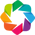

   season  avg_total_points  games_count weather_condition  \
0    2020         49.125000            8              Cold   
1    2021         49.285714           14              Cold   
2    2022         44.333333           21              Cold   
3    2023         41.222222            9              Cold   
4    2024         46.550000           20              Cold   

   avg_total_points_baseline  total_points_diff  
0                  47.155172           1.969828  
1                  45.821705           3.464009  
2                  41.950000           2.383333  
3                  43.149533          -1.927310  
4                  45.360000           1.190000  


In [36]:
import holoviews as hv
import panel as pn

hv.extension('bokeh')
pn.extension()

# Load the data
df = pd.read_csv('data/enriched_outdoor_games.csv')

# Calculate the trend data
trend_data = calculate_seasonal_trend(df)

# Now you can use trend_data for your visualizations
print(trend_data.head())

# Create interactive plot with Panel widget
conditions = ['All'] + trend_data['weather_condition'].unique().tolist()
condition_select = pn.widgets.Select(name='Select Weather Condition', options=conditions, value='All')

@pn.depends(condition_select.param.value)
def create_interactive_chart(selected_condition):
    if selected_condition == 'All':
        df_plot = trend_data.copy()
        group_by = 'weather_condition'
    else:
        df_plot = trend_data[trend_data['weather_condition'] == selected_condition].copy()
        group_by = None
    
    if df_plot.empty:
        return hv.Curve([], label='No data')
    
    # Create HoloViews dataset
    hv_data = hv.Dataset(df_plot, kdims=['season'], vdims=['total_points_diff', 'weather_condition', 'games_count', 'avg_total_points'])
    
    # Create curve plot
    if group_by:
        curve = hv_data.to(hv.Curve, kdims='season', vdims='total_points_diff', groupby=group_by).overlay()
    else:
        curve = hv_data.to(hv.Curve, kdims='season', vdims='total_points_diff')
    
    # Create scatter plot
    if group_by:
        scatter = hv_data.to(hv.Scatter, kdims='season', vdims='total_points_diff', groupby=group_by).overlay()
    else:
        scatter = hv_data.to(hv.Scatter, kdims='season', vdims='total_points_diff')
    
    # Zero line
    zero_line = hv.HLine(0).opts(color='gray', line_dash='dashed', line_width=1, alpha=0.7)
    
    # Combine plots
    combined = zero_line * curve * scatter
    final_chart = combined.opts(
        width=800, 
        height=500,
        title=f'Seasonal Trend: Change in Total Points ({selected_condition} vs. Normal)',
        xlabel='NFL Season',
        ylabel='Change in Total Points (vs. Normal)',
        show_grid=True,
        legend_position='right'
    ).options(
        {'Curve': {'line_width': 2, 'show_legend': True}},
        {'Scatter': {'size': 8, 'alpha': 0.7, 'show_legend': True}}
    )
    
    return final_chart




In [37]:
markdown_text = pn.pane.Markdown("""

""")

dashboard = pn.Column(
    markdown_text,
    condition_select,
    create_interactive_chart
)

dashboard

BokehModel(combine_events=True, render_bundle={'docs_json': {'b8312240-b8ca-4793-8fad-45c95d9986a5': {'version…